In [3]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [4]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer1.grib", engine="cfgrib")
var_daily1 = ds.swvl1.groupby(ds.swvl1.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer1.grib.5b7b6.idx' incompatible with GRIB file


In [5]:
ds = xr.load_dataset("ERA5_features/grib_files/soil_moist_layer2.grib", engine="cfgrib")
var_daily2 = ds.swvl2.groupby(ds.swvl2.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/soil_moist_layer2.grib.5b7b6.idx' incompatible with GRIB file


In [6]:
var_daily = var_daily1 + var_daily2
var_daily = var_daily.reset_coords(['number', 'step'], drop=True)

In [7]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [8]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [9]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))

In [10]:
ds_oro = xr.load_dataset("ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file 'ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [11]:
g = 9.80665
lat = ds_oro.latitude
land_frac = ds_oro.lsm
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)
land_filt = xr.where(land_frac > 0.5, 1, 0)

In [12]:
weights = np.cos(np.deg2rad(lat))*mount_filt*land_filt
weights.name = "weights"

In [13]:
lon_min = -10
lon_max = 10
lat_max = 47
lat_min = 36

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

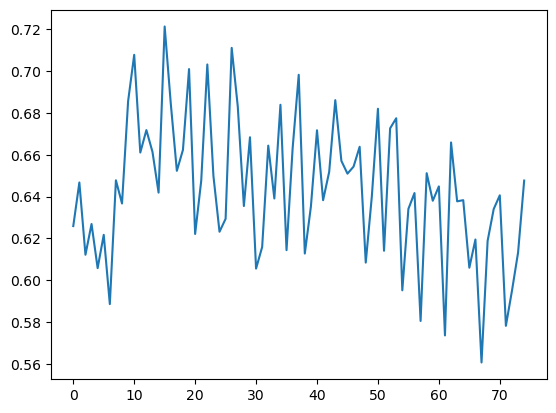

In [14]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)

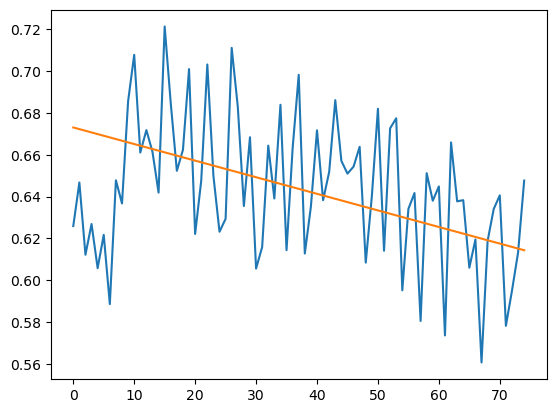

In [19]:
fit_par = np.polyfit(var_seasonmean_regmean[10:60].year, var_seasonmean_regmean[10:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, var_seasonmean_regmean.year)

plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)

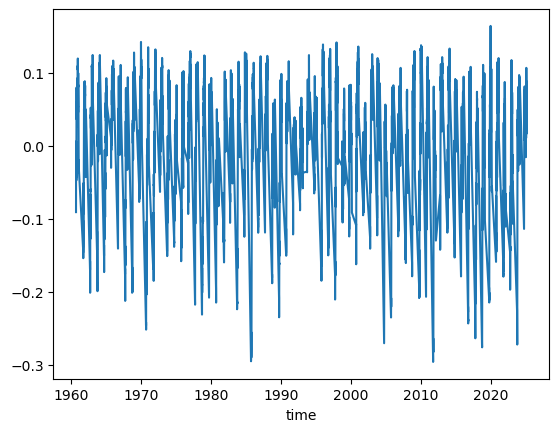

In [40]:
var_daily_regmean_detr = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_daily_regmean_detr = var_daily_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)
var_daily_regmean_detr[:151*10] = np.nan
var_daily_regmean_detr.plot()

In [41]:
var_7dMean_regmean_detr = var_daily_regmean_detr.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean_detr.time.dt.month
day = var_7dMean_regmean_detr.time.dt.day
var_7dMean_regmean_detr = var_7dMean_regmean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_detr_train = var_7dMean_regmean_detr.sel(time=slice("1960-07", "2010-06"))

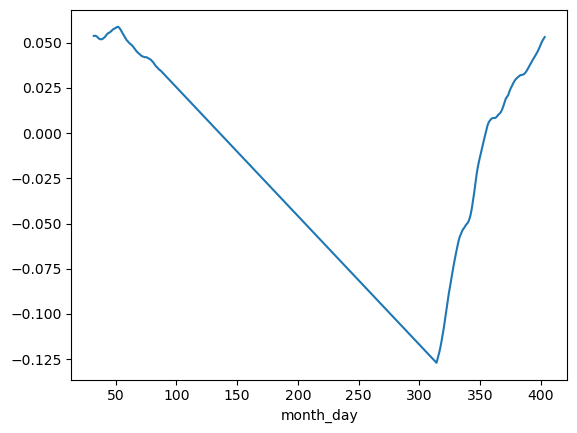

In [42]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr_train.groupby('month_day').mean()
var_7dMean_regmean_detr_train.groupby('month_day').mean().plot()

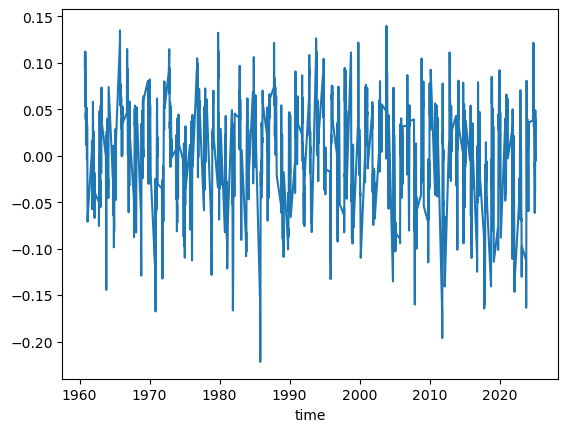

In [43]:
var_7dMean_regmean_detr_anom.plot()

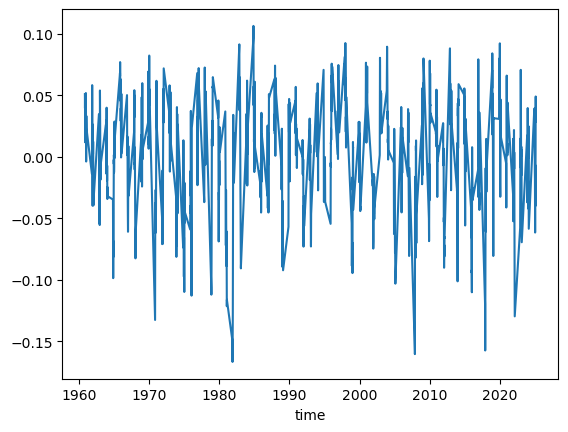

In [44]:
month = var_7dMean_regmean_detr_anom.time.dt.month
day = var_7dMean_regmean_detr_anom.time.dt.day
var_7dMean_regmean_detr_anom_week3 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_detr_anom_week3.plot()

In [45]:
df_var_week3 = var_7dMean_regmean_detr_anom_week3.to_dataframe(name='soil_moist_upper')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,soil_moist_upper
time,
1950-11-13,NaN
1950-11-14,NaN
1950-11-15,NaN
1950-11-16,NaN
1950-11-17,NaN
...,...
2025-01-31,0.048072
2025-02-01,0.044201
2025-02-02,0.039182


In [46]:
df_var_week3.to_csv('sm_upper_SWE_week3_detr.csv')